# 04 - Forecasting the Next Day's Renewable Share

**Energy Transition & Electric Mobility in Portugal**

**Target:** `pct_renewable` (renewable share of domestic production) for the next day.

| Model | Uses yesterday's value | Idea |
|---|---|---|
| Persistence | yes | tomorrow equals today |
| 7-day mean | yes | average of the previous 7 days |
| Linear regression | yes | yesterday's value, the previous 7-day mean, and the time of year (sine and cosine of the day of the year) |
| Climatology | no | training average of the same calendar month |
| Prophet | no | trend plus yearly seasonality |

The first three are **one-day-ahead** forecasts: each prediction uses the real value of the day before. Climatology and Prophet forecast a whole 60-day window at once, without seeing any recent values. That is a harder question, so they are reported apart rather than ranked against the others.

## Setup and data

In [1]:
import logging
import warnings
from pathlib import Path

# Prophet prints a progress-bar warning on import and two log lines per fit
warnings.filterwarnings("ignore", message="IProgress not found")
logging.getLogger("prophet.plot").disabled = True
logging.getLogger("cmdstanpy").disabled = True

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from prophet import Prophet
from sklearn.linear_model import LinearRegression

# Works whether the notebook sits in notebooks/ or in the project root
CWD = Path.cwd()
PROJECT_ROOT = CWD.parent if CWD.name == "notebooks" else CWD

DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#E6E6E6",
        "axes.axisbelow": True,
        "axes.titleweight": "bold",
        "legend.frameon": False,
    }
)

df_ren = pd.read_csv(
    DATA_PROCESSED / "ren_daily_production.csv", parse_dates=["date"]
).sort_values("date")

# One row per calendar day: a missing day becomes NaN instead of silently shifting the lags
series = df_ren.set_index("date")["pct_renewable"].asfreq("D")

print(
    f"Period: {series.index.min().date()} to {series.index.max().date()} ({len(series)} days)"
)
print(f"Days without data: {int(series.isna().sum())}")

Period: 2021-10-28 to 2026-10-28 (1827 days)
Days without data: 0


## Features

- `doy_sin`, `doy_cos`: day of the year placed on a circle, so 31 December and 1 January end up close together.
- `lag_1`: yesterday's value. `shift(1)` guarantees that only information from before the predicted day is used.
- `rolling_7`: average of the 7 days before the predicted day (needs at least 4 valid days).

In [2]:
FEATURES = ["doy_sin", "doy_cos", "lag_1", "rolling_7"]

feat = pd.DataFrame({"actual": series})
day_of_year = feat.index.dayofyear
feat["doy_sin"] = np.sin(2 * np.pi * day_of_year / 365.25)
feat["doy_cos"] = np.cos(2 * np.pi * day_of_year / 365.25)
feat["lag_1"] = series.shift(1)
feat["rolling_7"] = series.shift(1).rolling(7, min_periods=4).mean()
feat["month"] = feat.index.month

feat.dropna().head()

,actual,doy_sin,doy_cos,lag_1,rolling_7,month
date,,,,,,
2021-11-01,88.9,-0.860600,0.509282,96.3,81.050000,11
2021-11-02,73.0,-0.851712,0.524010,88.9,82.620000,11
2021-11-03,58.8,-0.842572,0.538584,73.0,81.016667,11
2021-11-04,64.0,-0.833183,0.552997,58.8,77.842857,11
2021-11-05,65.6,-0.823547,0.567248,64.0,78.457143,11


## Evaluation: walk-forward over many windows

A single test window can flatter or punish a model depending on how calm that period was. Instead, the most recent history is cut into consecutive 60-day windows. For each window, every model is trained only on the days before it (at least two years) and scored on the window itself. The windows are aligned to the end of the data, so the last one is always the latest 60 days.

In [3]:
TEST_DAYS = 60
MIN_TRAIN_DAYS = 730


def make_folds(index, test_days, min_train_days):
    """Consecutive test windows, counted back from the last day of the data."""
    earliest_start = index.min() + pd.Timedelta(days=min_train_days)
    folds, end = [], index.max()
    while end - pd.Timedelta(days=test_days - 1) >= earliest_start:
        start = end - pd.Timedelta(days=test_days - 1)
        folds.append((start, end))
        end = start - pd.Timedelta(days=1)
    return folds[::-1]


folds = make_folds(feat.index, TEST_DAYS, MIN_TRAIN_DAYS)
print(
    f"{len(folds)} windows of {TEST_DAYS} days, from {folds[0][0].date()} to {folds[-1][1].date()}"
)

18 windows of 60 days, from 2023-11-14 to 2026-10-28


## Models

Weekly and daily seasonality are switched off in Prophet: a weekday pattern in the daily renewable share would be noise rather than signal. The regression is refitted on every window, and its coefficients are printed for the latest one, because the point of a simple model is that it can be read.

In [4]:
def fit_prophet(train_series):
    model = Prophet(
        yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False
    )
    model.fit(train_series.rename_axis("ds").rename("y").reset_index())
    return model


def forecast_window(start, end):
    """Train every model on the days before `start` and predict each day from `start` to `end`."""
    train = feat[feat.index < start].dropna()
    test = feat[(feat.index >= start) & (feat.index <= end)].dropna()

    out = pd.DataFrame({"actual": test["actual"]})
    out["persistence"] = test["lag_1"]
    out["mean_7d"] = test["rolling_7"]

    regression = LinearRegression().fit(train[FEATURES], train["actual"])
    out["linear_regression"] = regression.predict(test[FEATURES])

    out["climatology"] = test["month"].map(train.groupby("month")["actual"].mean())
    out["prophet"] = (
        fit_prophet(train["actual"])
        .predict(pd.DataFrame({"ds": test.index}))["yhat"]
        .values
    )
    return out, regression


window_results = []
for number, (start, end) in enumerate(folds, start=1):
    predictions, regression = forecast_window(start, end)
    window_results.append(predictions.assign(window=number, window_start=start))

predictions_all = pd.concat(window_results)

coefficients = pd.Series(regression.coef_, index=FEATURES)
print("Linear regression, latest window:")
print(coefficients.round(3).to_string())
print(f"intercept {regression.intercept_:+.3f}")

Linear regression, latest window:
doy_sin      0.254
doy_cos      0.311
lag_1        0.683
rolling_7    0.246
intercept +5.544


## Results

`mae_pp` is the mean absolute error in percentage points, averaged over the windows. `bias_pp` is the mean signed error: negative means the model predicts too low on average. `windows_beating_persistence` counts the windows in which a model has a lower error than "tomorrow equals today".

In [5]:
MODELS = ["persistence", "mean_7d", "linear_regression", "climatology", "prophet"]
HORIZON = {
    "persistence": "1 day",
    "mean_7d": "1 day",
    "linear_regression": "1 day",
    "climatology": "60 days",
    "prophet": "60 days",
}

errors = predictions_all[MODELS].sub(predictions_all["actual"], axis=0)
window_mae = errors.abs().groupby(predictions_all["window_start"]).mean()

metrics = pd.DataFrame(
    {
        "horizon": pd.Series(HORIZON),
        "mae_pp": window_mae.mean(),
        "mae_latest_window_pp": window_mae.iloc[-1],
        "bias_pp": errors.mean(),
        "windows_beating_persistence": window_mae.lt(
            window_mae["persistence"], axis=0
        ).sum(),
    }
).loc[MODELS]
metrics.loc["persistence", "windows_beating_persistence"] = np.nan
metrics = metrics.sort_values(["horizon", "mae_pp"])

print(f"Evaluated on {len(folds)} windows ({len(predictions_all)} days)")
metrics.round(2)

Evaluated on 18 windows (1080 days)


,horizon,mae_pp,mae_latest_window_pp,bias_pp,windows_beating_persistence
persistence,1 day,2.63,2.66,0.02,NaN
linear_regression,1 day,2.86,2.49,-1.09,8.0
mean_7d,1 day,3.25,2.96,0.05,2.0
prophet,60 days,8.09,4.22,-0.42,0.0
climatology,60 days,12.50,8.32,-11.88,0.0


Regression vs persistence: average gain -0.23 pp per window (standard error 0.16), better in 8 of 18 windows


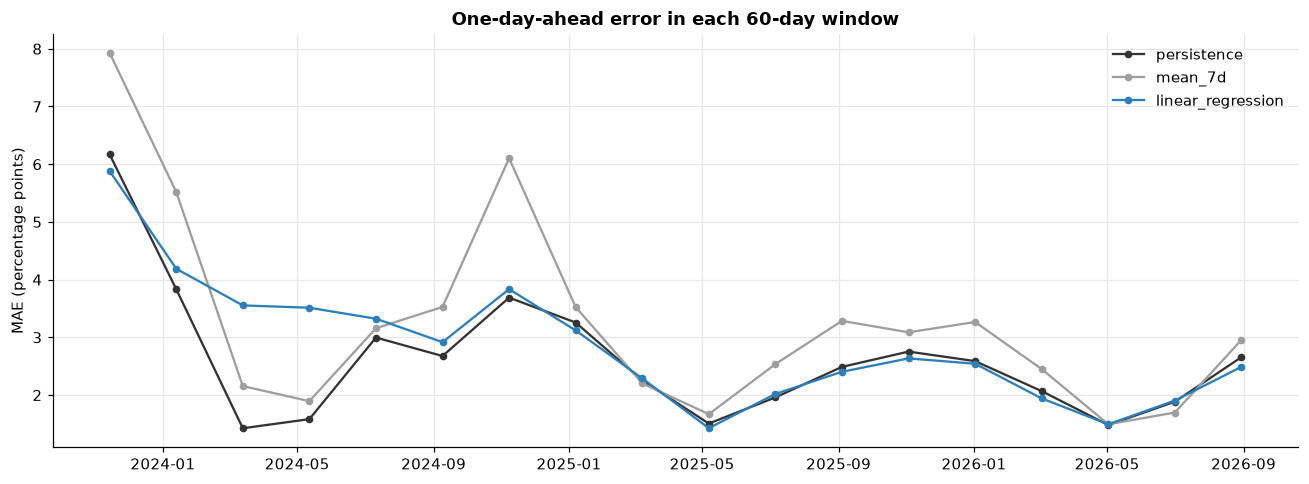

In [6]:
gain = window_mae["persistence"] - window_mae["linear_regression"]
standard_error = gain.std(ddof=1) / np.sqrt(len(gain))
print(
    f"Regression vs persistence: average gain {gain.mean():+.2f} pp per window "
    f"(standard error {standard_error:.2f}), better in {int((gain > 0).sum())} of {len(gain)} windows"
)

fig, ax = plt.subplots(figsize=(12, 4.5))
for model, color in [
    ("persistence", "#333333"),
    ("mean_7d", "#9E9E9E"),
    ("linear_regression", "#2C7FB8"),
]:
    ax.plot(
        window_mae.index,
        window_mae[model],
        marker="o",
        markersize=4,
        color=color,
        label=model,
    )
ax.set_ylabel("MAE (percentage points)")
ax.set_title("One-day-ahead error in each 60-day window")
ax.legend()
plt.tight_layout()
plt.show()

### Latest window in detail

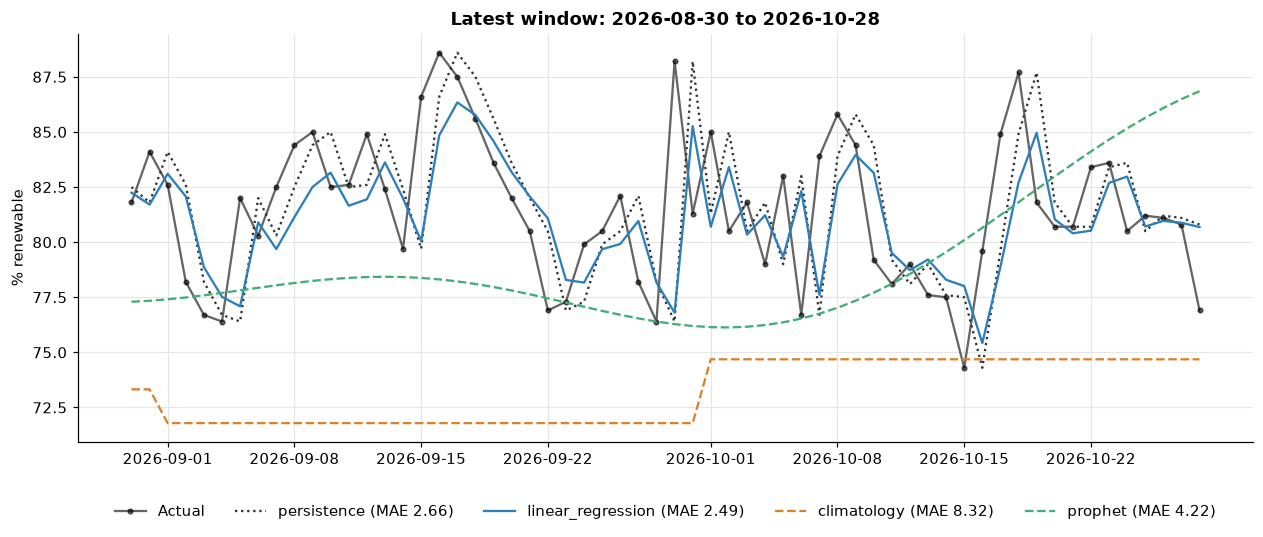

In [7]:
latest = predictions_all[predictions_all["window"] == len(folds)]

styles = {
    "persistence": ("#333333", ":"),
    "linear_regression": ("#2C7FB8", "-"),
    "climatology": ("#D9822B", "--"),
    "prophet": ("#41AE76", "--"),
}
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    latest.index,
    latest["actual"],
    color="black",
    marker="o",
    markersize=3,
    alpha=0.6,
    label="Actual",
)
for model, (color, style) in styles.items():
    mae = (latest[model] - latest["actual"]).abs().mean()
    ax.plot(
        latest.index,
        latest[model],
        color=color,
        linestyle=style,
        label=f"{model} (MAE {mae:.2f})",
    )
ax.set_ylabel("% renewable")
ax.set_title(
    f"Latest window: {latest.index.min().date()} to {latest.index.max().date()}"
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=5)
plt.tight_layout()
plt.show()

## Forecast for the next day

The one-day-ahead models are refitted on all the data and used to forecast the day after the last one available. This is the forecast the dashboard shows.

In [ ]:
last_day = series.index.max()
next_day = last_day + pd.Timedelta(days=1)

final_regression = LinearRegression().fit(
    feat.dropna()[FEATURES], feat.dropna()["actual"]
)
next_features = pd.DataFrame(
    {
        "doy_sin": [np.sin(2 * np.pi * next_day.dayofyear / 365.25)],
        "doy_cos": [np.cos(2 * np.pi * next_day.dayofyear / 365.25)],
        "lag_1": [series.loc[last_day]],
        "rolling_7": [series.iloc[-7:].mean()],
    }
)

next_day_forecast = pd.DataFrame(
    {
        "date": [next_day.date()],
        "based_on": [last_day.date()],
        "persistence": [series.loc[last_day]],
        "mean_7d": [series.iloc[-7:].mean()],
        "linear_regression": [final_regression.predict(next_features[FEATURES])[0]],
    }
)
next_day_forecast.round(2)

,date,based_on,persistence,mean_7d,linear_regression
0,2026-10-29,2026-10-28,76.9,81.07,77.93


## Save predictions and metrics for the dashboard

In [ ]:
# Every window is saved, so the dashboard can show any of them
predictions_all[["window", "window_start", "actual"] + MODELS].to_csv(
    DATA_PROCESSED / "model_predictions.csv", index_label="date"
)
metrics.to_csv(DATA_PROCESSED / "model_metrics.csv", index_label="model")
window_mae.round(3).to_csv(
    DATA_PROCESSED / "model_window_errors.csv", index_label="window_start"
)
next_day_forecast.to_csv(DATA_PROCESSED / "model_next_day.csv", index=False)
print(
    "Saved model_predictions.csv, model_metrics.csv, model_window_errors.csv and model_next_day.csv"
)

Saved model_predictions.csv, model_metrics.csv, model_window_errors.csv and model_next_day.csv


## Key findings

*From the run of 28 October 2026: 18 windows of 60 days, from 13 November 2023 to 27 October 2026.*

1. **"Tomorrow equals today" is the model to beat, and none of the others beats it consistently.** Persistence has the lowest average error, 2.62 percentage points. The linear regression averages 2.85 and beats persistence in 8 of the 18 windows. On average it is 0.23 points worse, with a standard error of 0.16, so the two are hard to tell apart.
2. **A single test window would have told the opposite story.** In the latest 60 days the regression comes out ahead (2.43 against 2.60). Looking at many windows is what shows that this lead is not reliable.
3. **The regression is close to a smoothed version of persistence.** It gives a weight of 0.68 to yesterday's value and 0.25 to the previous 7-day mean, and the time-of-year terms add little. It also predicts about 1 point too low on average.
4. **Without recent values, the error is three to five times larger.** Over a 60-day horizon, Prophet misses by 8.05 points on average and climatology by 12.52. Climatology is almost 12 points too low, because the older years it learns from had much less solar and wind.
5. **The next step for better forecasts is outside data.** Weather forecasts for wind, rain and sun drive the day-to-day changes in renewable output, and the series on its own has little more to offer for next-day forecasts.

## Limits

- The renewable share changes slowly from one day to the next, which makes "tomorrow equals today" hard to beat. Any one-day-ahead model has to be judged against it, not against the long-horizon models.
- The models only learn from the series itself. They cannot anticipate external events, such as the rise in gas production after the April 2025 blackout, or rain and wind forecasts, which would be the obvious next features.
- Climatology and Prophet learn from older years with less solar and wind capacity, so they tend to predict too low when the share has grown structurally.
- Results move as the extraction window rolls forward, so models should only be compared within the same run.